# Inject Gaussian, triangular, and exocomet profiles

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


Truth-labeled samples: 98


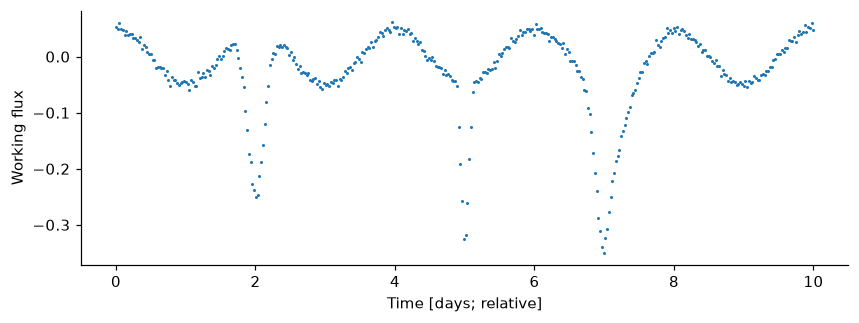

In [2]:
# Generate a low-amplitude baseline with white noise and no correlated red noise.
lc = Nahiku.from_synthetic_noise(n_points=400, amplitude=.05, white_noise=.005, red_noise=0)

# Inject three dips at separate times; "saw" selects the symmetric triangular profile.
# Each depth is 0.3 working flux units; the exocomet egress timescale is 2 * 0.12 day.
for center, shape in [(2, "gaussian"), (5, "saw"), (7, "exocomet")]:
    lc.inject_anomaly(center=center, width=.12, depth=.3, shape=shape, alpha=2)

# Plot the working light curve after all three additive injections.
lc.plot();

# Count samples in the combined injection-support mask, not the number of events.
print("Truth-labeled samples:", lc.truth_mask.sum())

## Interpret the result

The three dips are Gaussian at day 2, triangular (`shape="saw"`) at day 5, and exocomet-like at day 7. Width is Gaussian sigma, triangular half-width, or exocomet ingress sigma; equal widths do not imply equal event durations. For this exocomet injection, the exponential egress timescale is `alpha * width = 0.24` day.

Depth is an additive decrement in working flux units, not necessarily a fractional transit depth. The sampled minimum need not reach the specified depth if the center falls between observations. The exocomet shape follows the empirical Gaussian–exponential template of [Kennedy et al. (2019), equation 6](https://doi.org/10.1093/mnras/sty3049), before numerical truncation; it is not a complete physical dust-transit model.

Each injection changes working flux, preserves original observations, and invalidates existing fitted results. Contributions below 1% of peak depth are set to zero; the retained support is accumulated in `truth_mask`. Overlapping supports merge, so the mask records affected samples rather than a separate label for each injection.

Consult the API reference for parameter and return-value details.